# 12. 사람 단위 3-fold 교차검증 1단계: 전처리 비교(CV1)

공식 Val은 운동마다 한 사람이라, P1(10번 노트북)의 판정은 사실상 그 한 사람에 대한 결과였습니다. 여기서는 Train과 Val을 합친 19명을 세 fold로 나눕니다. fold마다 검증 사람은 클래스별 2명 이상입니다. 같은 전처리 6개를 다시 비교합니다.

- 분할: `data/splits/cv3_folds.csv`(고정, 검사 14항목 통과). Test 3명은 넣지 않았습니다(E08 동결).
- 조건: Full FT, seed 42. 전처리만 바꾸고 나머지는 후보 A와 같습니다. 실행 ID는 `CV1-<이름>-f<fold>`입니다.
- **짝 비교**: Δ_f = F1(후보, fold f) − F1(letterbox, fold f). fold와 seed가 같습니다.
- **분류 기준(실행 전 `experiments/CV/PLAN.md`)**

| 분류 | 조건 |
|---|---|
| 일관 개선형 | 세 fold 모두 Δ_f > 0 |
| 평균 개선형 | Δ_f > 0인 fold 2개 이상, 평균 Δ ≥ +0.010 |
| 효율 개선형 | 평균 Δ > −0.010, epoch당 학습 시간 ≤ 기준의 0.7배 |
| 나쁨 | Δ_f < 0인 fold 2개 이상, 평균 Δ ≤ −0.010 |
| 차이 없음 | 그 밖(재검증 예외: 평균 Δ ≥ +0.005이고 개선 fold가 2개 이상) |

- 붕괴 표시: 어떤 클래스든 Recall < 0.20인 fold가 2개 이상
- fold 점수는 Early Stopping과 같은 데이터로 매긴 것이라 낙관적입니다. 후보 사이 비교용이고, Test 성능이 아닙니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 220)
NAMES = class_names()
EXP = ROOT / "experiments"
PRE = {"letterbox": ("letterbox", 224, 224 * 224), "stretch": ("stretch", 224, 224 * 224), "aspect224": ("aspect", 224, 224 * 126),
       "aspect384": ("aspect", 384, 384 * 216), "ccrop": ("ccrop", 224, 224 * 224), "gray": ("gray", 224, 224 * 224)}
rows = []
for name, (pre, size, px) in PRE.items():
    for f in (1, 2, 3):
        rid = f"CV1-{name}-f{f}"; dd = EXP / rid / "full"
        sm = json.loads((dd / "summary.json").read_text(encoding="utf-8")); cf = json.loads((dd / "config.json").read_text(encoding="utf-8"))
        assert (cf["cv_fold"], cf["preprocess"], cf["input_size"], cf["seed"]) == (f, pre, size, 42), rid
        h = pd.read_csv(dd / "history.csv")
        rec = sm["val"]["per_class"]["recall"]
        rows.append({"전처리": name, "fold": f, "Macro F1": sm["val"]["macro_f1"], "Acc": sm["val"]["accuracy"],
                     "최저 Recall": min(rec.values()), "최저 클래스": min(rec, key=rec.get),
                     "덤벨 로우": rec["덤벨 벤트오버 로우"], "데드리프트": rec["바벨 데드리프트"], "바벨 로우": rec["바벨 로우"],
                     "best/last epoch": f"{sm['best_epoch']}/{sm['epochs_run']}",
                     "Best−Last F1": sm["val"]["macro_f1"] - h.val_macro_f1.iloc[-1],
                     "epoch당(초)": sm["mean_train_epoch_s"], "전체(분)": sm["total_time_s"] / 60, "입력 픽셀": px})
cv = pd.DataFrame(rows)
cv.round(3)

font: Malgun Gothic


,전처리,fold,Macro F1,Acc,최저 Recall,최저 클래스,덤벨 로우,데드리프트,바벨 로우,best/last epoch,Best−Last F1,epoch당(초),전체(분),입력 픽셀
0,letterbox,1,0.819,0.868,0.367,바벨 로우,0.450,0.881,0.367,7/12,0.005,8.569,2.880,50176
1,letterbox,2,0.873,0.890,0.305,바벨 로우,0.850,0.597,0.305,5/10,0.009,9.308,2.372,50176
2,letterbox,3,0.842,0.880,0.266,바벨 로우,0.791,0.441,0.266,13/18,0.004,7.956,4.109,50176
3,stretch,1,0.828,0.882,0.267,바벨 로우,0.528,0.925,0.267,7/12,0.013,8.516,2.854,50176
4,stretch,2,0.884,0.900,0.383,바벨 로우,0.847,0.653,0.383,18/23,0.006,8.426,5.269,50176
5,stretch,3,0.875,0.909,0.344,바벨 로우,0.825,0.634,0.344,13/18,0.003,7.974,4.178,50176
6,aspect224,1,0.824,0.869,0.350,바벨 로우,0.588,0.744,0.350,2/7,0.011,7.132,1.430,28224
7,aspect224,2,0.873,0.894,0.242,바벨 로우,0.684,0.803,0.242,9/14,0.009,6.406,2.563,28224
8,aspect224,3,0.851,0.893,0.211,바벨 로우,0.728,0.700,0.211,6/11,0.003,6.369,2.125,28224
9,aspect384,1,0.865,0.905,0.283,바벨 로우,0.800,0.750,0.283,2/7,0.009,13.160,2.224,82944


## 1. 짝 비교와 분류

In [2]:
base = cv[cv["전처리"] == "letterbox"].set_index("fold")
out = []
for name in PRE:
    g = cv[cv["전처리"] == name].set_index("fold")
    dlt = g["Macro F1"] - base["Macro F1"]
    pos, neg, m = int((dlt > 0).sum()), int((dlt < 0).sum()), dlt.mean()
    t_ratio = g["epoch당(초)"].mean() / base["epoch당(초)"].mean()
    if name == "letterbox":
        cls = "기준"
    elif pos == 3:
        cls = "일관 개선형"
    elif pos >= 2 and m >= 0.010:
        cls = "평균 개선형"
    elif m > -0.010 and t_ratio <= 0.7:
        cls = "효율 개선형"
    elif neg >= 2 and m <= -0.010:
        cls = "나쁨"
    else:
        cls = "차이 없음" + (" (재검증 예외)" if (m >= 0.005 and pos >= 2) else "")
    collapse = int((g["최저 Recall"] < 0.20).sum())
    out.append({"전처리": name, "F1 평균": g["Macro F1"].mean(), "Δ f1": dlt[1], "Δ f2": dlt[2], "Δ f3": dlt[3], "평균 Δ": m,
                "Δ 범위": dlt.max() - dlt.min(), "개선 fold": pos, "시간 비율": t_ratio, "붕괴 fold": collapse,
                "분류": cls + (", 붕괴 경향" if collapse >= 2 else ""),
                "Best−Last 평균": g["Best−Last F1"].mean()})
res = pd.DataFrame(out).set_index("전처리")
res.round(4)

,F1 평균,Δ f1,Δ f2,Δ f3,평균 Δ,Δ 범위,개선 fold,시간 비율,붕괴 fold,분류,Best−Last 평균
전처리,,,,,,,,,,,
letterbox,0.8449,0.0000,0.0000,0.0000,0.0000,0.0000,0,1.0000,0,기준,0.0058
stretch,0.8626,0.0089,0.0110,0.0331,0.0177,0.0242,3,0.9644,0,일관 개선형,0.0070
aspect224,0.8494,0.0052,-0.0005,0.0090,0.0046,0.0094,2,0.7706,0,차이 없음,0.0078
aspect384,0.8760,0.0460,0.0209,0.0264,0.0311,0.0251,3,1.4681,1,일관 개선형,0.0090
ccrop,0.8806,0.0817,0.0028,0.0225,0.0357,0.0788,3,1.0243,2,"일관 개선형, 붕괴 경향",0.0190
gray,0.8457,0.0153,-0.0152,0.0023,0.0008,0.0305,2,0.9774,1,차이 없음,0.0229


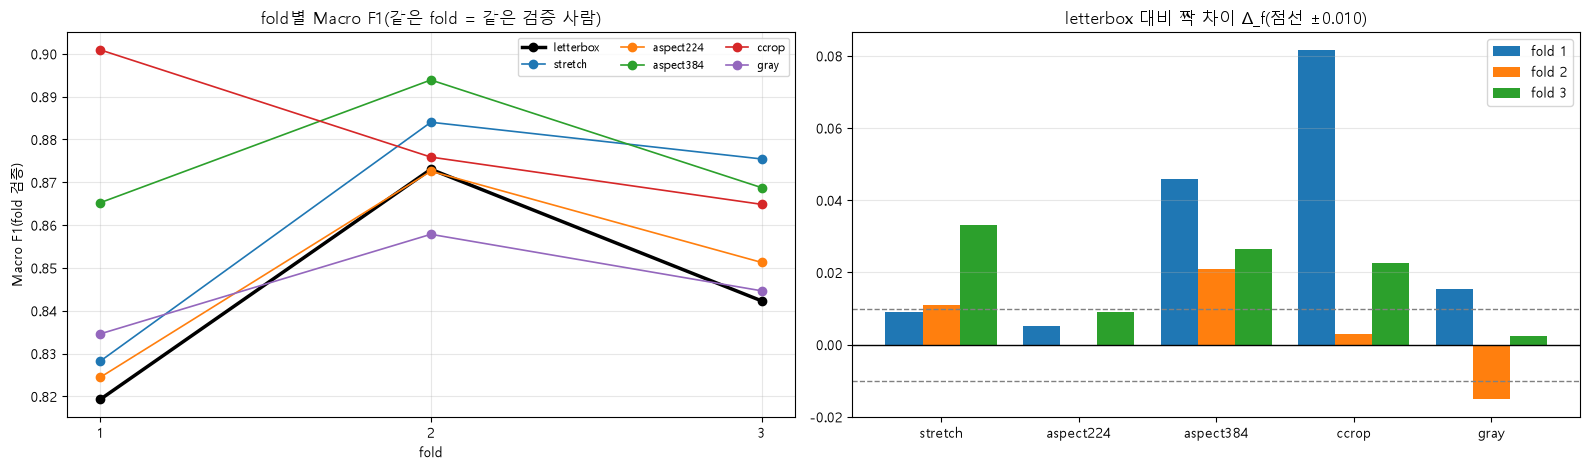

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for name in PRE:
    g = cv[cv["전처리"] == name]
    axes[0].plot(g["fold"], g["Macro F1"], marker="o", lw=2.5 if name == "letterbox" else 1.2,
                 color="k" if name == "letterbox" else None, label=name)
axes[0].set_xticks([1, 2, 3]); axes[0].set_xlabel("fold"); axes[0].set_ylabel("Macro F1(fold 검증)"); axes[0].legend(ncol=3, fontsize=8)
axes[0].set_title("fold별 Macro F1(같은 fold = 같은 검증 사람)"); axes[0].grid(alpha=.3)
names = [n for n in PRE if n != "letterbox"]
x = np.arange(len(names))
for k, f in enumerate((1, 2, 3)):
    axes[1].bar(x + (k - 1) * 0.27, res.loc[names, f"Δ f{f}"], 0.27, label=f"fold {f}")
axes[1].axhline(0, color="k", lw=1); axes[1].axhline(0.01, color="gray", ls="--", lw=1); axes[1].axhline(-0.01, color="gray", ls="--", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels(names); axes[1].legend(); axes[1].set_title("letterbox 대비 짝 차이 Δ_f(점선 ±0.010)")
axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIGURES / "cv1_preprocessing.png", dpi=110); plt.show()

## 2. 공식 Val(P1)과 CV의 판정 비교

In [4]:
p1 = {"stretch": "구분 불가", "aspect224": "나쁨", "aspect384": "구분 불가, 붕괴 경향", "ccrop": "좋음", "gray": "나쁨"}
pd.DataFrame({"P1(공식 Val, seed 3)": p1, "CV1(19명, seed 1)": res.loc[list(p1), "분류"], "CV1 평균 Δ": res.loc[list(p1), "평균 Δ"].round(4)})

,"P1(공식 Val, seed 3)","CV1(19명, seed 1)",CV1 평균 Δ
stretch,구분 불가,일관 개선형,0.0177
aspect224,나쁨,차이 없음,0.0046
aspect384,"구분 불가, 붕괴 경향",일관 개선형,0.0311
ccrop,좋음,"일관 개선형, 붕괴 경향",0.0357
gray,나쁨,차이 없음,0.0008


## 3. 클래스별 Recall(fold 3개 평균)

In [5]:
order = [c for g in GROUPS.values() for c in g]
tab = {}
for name in PRE:
    r = np.array([[json.loads((EXP / f"CV1-{name}-f{f}" / "full" / "summary.json").read_text(encoding="utf-8"))["val"]["per_class"]["recall"][NAMES[c]]
                   for c in order] for f in (1, 2, 3)])
    tab[name] = [f"{m:.2f}±{s:.2f}" for m, s in zip(r.mean(0), r.std(0, ddof=1))]
pd.DataFrame(tab, index=[f"{c} {NAMES[c]}" for c in order])

,letterbox,stretch,aspect224,aspect384,ccrop,gray
0 Y - Exercise,0.95±0.08,0.97±0.01,0.96±0.03,0.97±0.02,0.98±0.01,0.97±0.00
1 니푸쉬업,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
4 라잉 레그 레이즈,0.83±0.19,0.84±0.16,0.83±0.16,0.89±0.08,0.95±0.02,0.88±0.11
10 바이시클 크런치,0.84±0.12,0.81±0.08,0.82±0.07,0.86±0.11,0.85±0.10,0.77±0.16
2 덤벨 벤트오버 로우,0.70±0.22,0.73±0.18,0.67±0.07,0.84±0.08,0.86±0.03,0.71±0.15
7 바벨 데드리프트,0.64±0.22,0.74±0.16,0.75±0.05,0.75±0.04,0.84±0.07,0.66±0.14
8 바벨 런지,0.97±0.02,0.98±0.00,0.97±0.02,0.97±0.02,0.99±0.00,0.95±0.03
9 바벨 로우,0.31±0.05,0.33±0.06,0.27±0.07,0.28±0.14,0.15±0.12,0.25±0.06
3 딥스,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
5 랫풀 다운,0.99±0.00,0.99±0.01,0.99±0.01,0.99±0.01,0.99±0.01,0.99±0.01


## 4. 해석(2026-11-26, 1단계 18회 결과)

### 판정
- **일관 개선형 3개**: aspect384(+0.031), stretch(+0.018), ccrop(+0.036, 다만 **붕괴 경향**)
- **차이 없음 2개**: aspect224(+0.005), gray(+0.001)
- 규칙대로 개선형 3개와 기준을 2단계(seed 43·44 추가, 24회)로 재검증합니다(`scripts/run_cv2.sh`).

### 공식 Val(P1)과 판정이 크게 달랐습니다
| 전처리 | P1(공식 Val, 운동마다 1명) | CV1(19명, fold당 클래스별 2명 이상) |
|---|---|---|
| stretch | 구분 불가 | 일관 개선 |
| aspect384 | 구분 불가, 붕괴 경향 | 일관 개선 |
| gray | 나쁨(−0.051) | 차이 없음 |
| ccrop | 좋음 | 일관 개선, 붕괴 경향 |

- 같은 전처리라도 **누구를 검증하느냐에 따라 결론이 뒤집혔습니다.** 특히 바벨·덤벨 묶음은 공식 Val에서 Z23 한 사람뿐이었습니다. P1의 판정은 "Z23에게 무엇이 맞는가"에 가까웠던 셈입니다.
- 사람 단위 교차검증을 도입한(D-037) 이유가 실제 결과로 확인됐습니다. 지금까지의 공식 Val 결론(E05~E07, P1)도 이 한계를 안고 읽어야 합니다.
- 다만 CV1도 seed 하나라서, 판정은 2단계 결과로 내립니다.

### 바벨 로우는 어느 전처리에서도 약합니다
- 기준(letterbox)의 바벨 로우 Recall은 fold 평균 0.31입니다. 개선형 세 전처리도 0.15~0.33에 머뭅니다.
- **ccrop은 다른 클래스를 크게 올리고 바벨 로우를 잃었습니다**(덤벨 로우 0.70→0.86, 데드리프트 0.64→0.84, 바벨 로우 0.31→0.15). fold 2·3에서는 Recall이 0.156·0.023으로 붕괴 기준(0.20) 아래입니다. "오류가 사라지지 않고 자리를 옮긴다"(E07)는 패턴이 사람을 바꿔도 반복됩니다.
- aspect384는 바벨 로우를 크게 잃지 않으면서(0.28) 덤벨 로우·데드리프트를 올렸습니다(0.84, 0.75). 대신 epoch 시간이 1.47배입니다.

### Early Stopping 낙관(Best − Last)
- 대부분 0.01 안팎입니다. ccrop(0.019)과 gray(0.023)는 조금 더 큽니다. fold 1에서 각각 0.039, 0.052로, 최고 시점이 운 좋게 걸렸을 가능성을 2단계에서 함께 봅니다.